In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Dataset inladen
df = pd.read_csv("forest_area_cleaned.csv")

# Eerste 5 rijen bekijken
df.head()

,area_name,area_code,year,forest_area
0,Afghanistan,AFG,1990,12084.4
1,Albania,ALB,1990,7888.0
2,Algeria,DZA,1990,16670.0
3,American Samoa,ASM,1990,180.7
4,Andorra,AND,1990,160.0


In [3]:
# Alleen de wereld selecteren
wereld = df[df["area_name"] == "World"].copy()

# Alleen 1990 tot en met 2020
wereld = wereld[
    (wereld["year"] >= 1990) &
    (wereld["year"] <= 2020)
]

# Ontbrekende waarden verwijderen
wereld = wereld.dropna(subset=["forest_area"])

# Sorteren op jaar
wereld = wereld.sort_values("year")

wereld.head()


,area_name,area_code,year,forest_area
797,World,WLD,1992,4.203424e+07
1063,World,WLD,1993,4.200109e+07
1329,World,WLD,1994,4.192261e+07
1595,World,WLD,1995,4.184413e+07
1861,World,WLD,1996,4.176565e+07


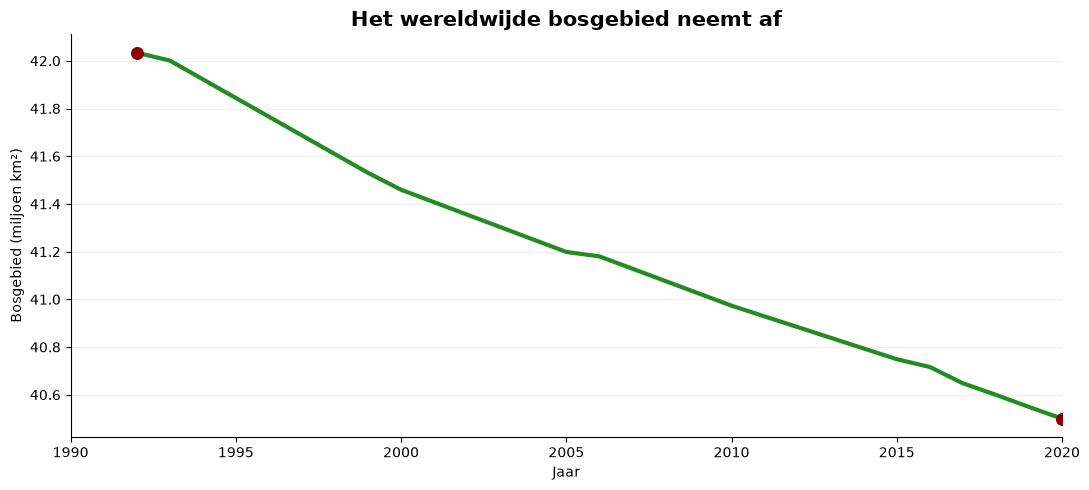

In [10]:
# Grafiek maken
plt.figure(figsize=(11, 5))

# Wereldwijd bosgebied tekenen
plt.plot(
    wereld["year"],
    wereld["forest_area"] / 1000000,
    color="forestgreen",
    linewidth=3
)

# Beginpunt en eindpunt benadrukken
plt.scatter(
    [wereld["year"].iloc[0], wereld["year"].iloc[-1]],
    [wereld["forest_area"].iloc[0] / 1000000,
     wereld["forest_area"].iloc[-1] / 1000000],
    color="darkred",
    s=70,
    zorder=3
)

# Titel en assen
plt.title(
    "Het wereldwijde bosgebied neemt af",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Jaar")
plt.ylabel("Bosgebied (miljoen km²)")

# Alleen lichte horizontale rasterlijnen
plt.grid(axis="y", alpha=0.2)

# Onnodige randen verwijderen
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.xlim(1990, 2020)

plt.tight_layout()
plt.show()


### Opdracht A – Wereldwijd bosgebied (1990–2020)

Voor deze opdracht heb ik een lijngrafiek gemaakt die de ontwikkeling van het wereldwijde bosgebied laat zien. De beschikbare gegevens tonen een afname van het bosgebied.

**Grafiekkeuze:** Ik heb een lijngrafiek gekozen omdat deze geschikt is om veranderingen over een langere periode te laten zien. Hierdoor kunnen VN-leiders de ontwikkeling van het wereldwijde bosgebied volgen en zien of de afname doorzet.

**Context:** De afname van bosgebied is belangrijk voor klimaatbeleid en biodiversiteit. Bossen slaan CO₂ op en bieden leefgebieden aan veel planten- en diersoorten. De grafiek kan VN-leiders helpen om het belang van bosbescherming te beoordelen.

**Clutter:** Ik heb de bovenste en rechterrand verwijderd, omdat deze geen extra informatie geven. Ook heb ik alleen lichte horizontale rasterlijnen gebruikt. Het bosgebied is weergegeven in miljoenen km², zodat de getallen gemakkelijker leesbaar zijn.

**Preattentive attributes:** De groene lijn laat de ontwikkeling van het bosgebied zien. Met rode punten worden het begin en het einde van de beschikbare periode benadrukt. Het kleurcontrast en de dikkere lijn helpen om de aandacht op de belangrijkste ontwikkeling te richten.

**Ontbrekende gegevens:** De waarden voor 1990 en 1991 ontbreken in de dataset. Daarom begint de lijn in 1992. Deze ontbrekende waarden zijn niet zelf ingevuld.

📊 Opdracht B – Bosgebied per inkomensniveau (1990–2020)

In [ ]:
# De vijf inkomensgroepen
groepen = [
    "Low income",
    "Lower middle income",
    "Middle income",
    "Upper middle income",
    "High income"
]

# Alleen deze groepen selecteren
inkomen = df[df["area_name"].isin(groepen)].copy()

# Alleen 1990 tot en met 2020
inkomen = inkomen[
    (inkomen["year"] >= 1990) &
    (inkomen["year"] <= 2020)
]

# Ontbrekende waarden verwijderen
inkomen = inkomen.dropna(subset=["forest_area"])

# Bekijken welke groepen gevonden zijn
print(inkomen["area_name"].unique())

inkomen.head()

,area_name,area_code,year,forest_area
233,High income,HIC,1990,1.011042e+07
245,Low income,LIC,1990,3.523832e+06
246,Lower middle income,LMC,1990,6.237384e+06
250,Middle income,MIC,1990,NaN
264,Upper middle income,UMC,1990,NaN


groepen bevat de vijf inkomensgroepen.
isin(groepen) zoekt de rijen die bij deze groepen horen.
inkomen slaat de geselecteerde gegevens op.
head() laat de eerste vijf rijen zien.

In [6]:
# Bekijken welke inkomensgroepen gevonden zijn
print(inkomen["area_name"].unique())

<ArrowStringArray>
[        'High income',          'Low income', 'Lower middle income',
       'Middle income', 'Upper middle income']
Length: 5, dtype: str


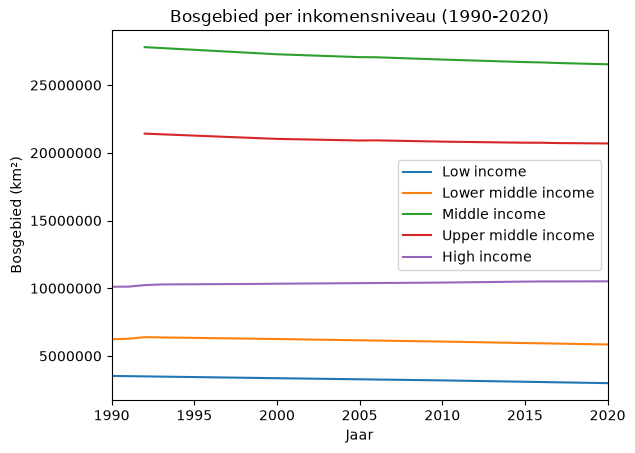

In [ ]:
# Grafiek maken
plt.figure(figsize=(12, 6))

# Kleuren voor de inkomensgroepen
kleuren = [
    "red",
    "orange",
    "purple",
    "steelblue",
    "forestgreen"
]

# Grafiek maken voor de vijf inkomensgroepen
for groep, kleur in zip(groepen, kleuren):

    data = inkomen[inkomen["area_name"] == groep]
    data = data.sort_values("year")

    plt.plot(
        data["year"],
        data["forest_area"] / 1000000,
        label=groep,
        color=kleur,
        linewidth=2.5
    )

# Titel en assen
plt.title(
    "Ontwikkeling van bosgebied per inkomensniveau (1990–2020)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Jaar")
plt.ylabel("Bosgebied (miljoen km²)")

# Legenda
plt.legend(
    title="Inkomensniveau",
    frameon=False
)

# Lichte rasterlijnen
plt.grid(axis="y", alpha=0.2)

# Onnodige randen verwijderen
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.xlim(1990, 2020)

plt.tight_layout()
plt.show()

### Opdracht B – Bosgebied per inkomensniveau (1990–2020)

Voor deze opdracht heb ik een lijngrafiek gemaakt waarin vijf inkomensgroepen worden vergeleken. De grafiek laat zien hoe het bosgebied zich tussen 1990 en 2020 per inkomensgroep heeft ontwikkeld.

**Grafiekkeuze:** Ik heb gekozen voor een lijngrafiek met vijf lijnen omdat deze geschikt is om ontwikkelingen over meerdere jaren te vergelijken. Hierdoor kunnen VN-leiders zien hoe de bosoppervlakte per inkomensgroep verandert.

**Context:** De ontwikkeling van het bosgebied verschilt per inkomensgroep. Deze verschillen zijn relevant voor internationale klimaatmaatregelen, omdat landen met verschillende inkomensniveaus mogelijk andere middelen en ondersteuning nodig hebben voor bosbescherming.

**Clutter:** Ik heb de bovenste en rechterrand verwijderd en alleen lichte horizontale rasterlijnen gebruikt. Ook heb ik de waarden weergegeven in miljoenen km², zodat grote getallen gemakkelijker leesbaar zijn.

**Preattentive attributes:** Ik heb vijf verschillende kleuren gebruikt om de inkomensgroepen te onderscheiden. De lijnen hebben dezelfde dikte, zodat de groepen visueel gelijkwaardig worden behandeld. De richting en positie van de lijnen maken verschillen in ontwikkeling zichtbaar.

**Ontbrekende gegevens:** Sommige waarden ontbreken in de dataset. Deze zijn niet zelf ingevuld. De categorie Middle income overlapt bovendien met Lower middle income en Upper middle income. De vijf groepen kunnen daarom niet allemaal bij elkaar worden opgeteld.

📊 Volgende: Opdracht C – Landen vergelijken (2018–2020)

In [ ]:
# Landen selecteren
landen = ["Netherlands", "Germany", "Brazil", "World"]

vergelijking = df[
    (df["area_name"].isin(landen)) &
    (df["year"].between(2018, 2020))
].copy()

# Ontbrekende waarden verwijderen
vergelijking = vergelijking.dropna(subset=["forest_area"])

# Bosgebied van 2018 als basis nemen
basis = vergelijking[vergelijking["year"] == 2018]
basis = basis.set_index("area_name")["forest_area"]

# Index berekenen
vergelijking["index"] = vergelijking.apply(
    lambda rij: rij["forest_area"] / basis[rij["area_name"]] * 100,
    axis=1
)

# Grafiek maken
plt.figure(figsize=(11, 6))

kleuren = {
    "Netherlands": "steelblue",
    "Germany": "orange",
    "Brazil": "red",
    "World": "forestgreen"
}

for land in landen:
    data = vergelijking[vergelijking["area_name"] == land]
    data = data.sort_values("year")

    plt.plot(
        data["year"],
        data["index"],
        marker="o",
        linewidth=2.5,
        color=kleuren[land],
        label=land
    )

plt.axhline(100, color="gray", linestyle="--", alpha=0.5)

plt.title("Verandering van bosgebied (2018–2020)")
plt.xlabel("Jaar")
plt.ylabel("Bosgebied (index: 2018 = 100)")

plt.xticks([2018, 2019, 2020])
plt.legend(frameon=False)
plt.grid(axis="y", alpha=0.2)

plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

,area_name,area_code,year,forest_area
7474,Brazil,BRA,2018,4.990514e+06
7521,Germany,DEU,2018,1.141900e+05
7587,Netherlands,NLD,2018,3.676300e+03
7713,World,WLD,2018,4.059955e+07
7740,Brazil,BRA,2019,4.977985e+06


Omdat de wereld veel meer bosgebied heeft dan Nederland, gebruiken we vier kleine lijngrafieken naast elkaar in één figuur. Zo kun je de ontwikkeling van 2018 tot 2020 per gebied goed bekijken.

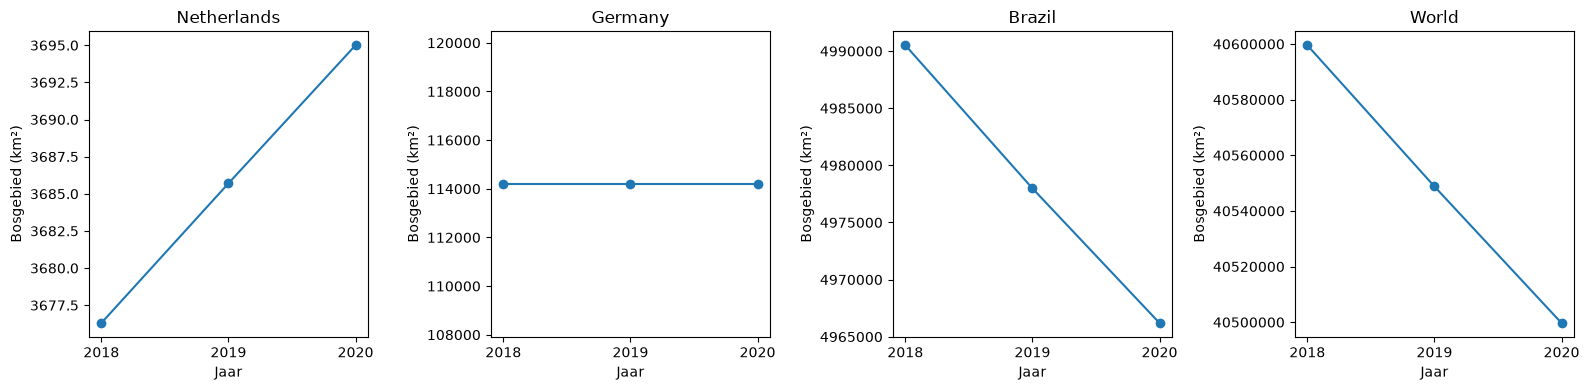

In [9]:
# Vier grafieken maken
fig, assen = plt.subplots(1, 4, figsize=(16, 4))

# Voor ieder land een grafiek
for i, land in enumerate(landen):
    data = vergelijking[vergelijking["area_name"] == land]

    assen[i].plot(data["year"], data["forest_area"], marker="o")
    assen[i].set_title(land)
    assen[i].set_xlabel("Jaar")
    assen[i].set_ylabel("Bosgebied (km²)")
    assen[i].set_xticks([2018, 2019, 2020])
    assen[i].ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

| Code | Betekenis |
|---|---|
| `plt.subplots(1, 4)` | Maakt vier grafieken naast elkaar |
| `for` | Herhaalt de code voor ieder land |
| `enumerate(landen)` | Geeft ieder land een nummer |
| `plt.plot()` | Maakt een lijngrafiek |
| `marker="o"` | Zet een punt bij ieder jaar |
| `set_title()` | Zet de naam van het land boven de grafiek |
| `set_xticks()` | Toont 2018, 2019 en 2020 |
| `plt.tight_layout()` | Zorgt dat de grafieken netjes passen |

### Opdracht C – Bosgebied vergelijken (2018–2020)

Voor deze opdracht heb ik het bosgebied van Nederland, Duitsland, Brazilië en de wereld vergeleken tussen 2018 en 2020.

**Grafiekkeuze:** Ik heb eerst vier kleine lijngrafieken gemaakt waarin het bosgebied in km² wordt weergegeven. Omdat de gebieden sterk verschillen in grootte, heb ik daarnaast een indexgrafiek gebruikt. Hierbij is het bosgebied van 2018 voor ieder gebied gelijkgesteld aan 100. Zo kunnen de relatieve veranderingen beter worden vergeleken.

**Context:** De eerste grafieken laten zien dat het bosgebied in Nederland toeneemt, in Duitsland vrijwel gelijk blijft en in Brazilië en wereldwijd afneemt. Dit is relevant voor VN-leiders omdat de ontwikkeling van het bosgebied per gebied verschilt.

**Clutter:** Ik heb de grafieken overzichtelijk gehouden door alleen de jaren 2018, 2019 en 2020 weer te geven. Bij de indexgrafiek heb ik onnodige randen verwijderd en lichte rasterlijnen gebruikt.

**Preattentive attributes:** Ik heb verschillende kleuren gebruikt om de gebieden te onderscheiden. De punten benadrukken de afzonderlijke jaren. De grijze stippellijn bij index 100 maakt duidelijk of het bosgebied is gestegen of gedaald ten opzichte van 2018.

**Beperking:** De eerste vier grafieken gebruiken verschillende verticale schalen. Daardoor zijn de absolute verschillen minder gemakkelijk te vergelijken. De indexgrafiek lost dit gedeeltelijk op, maar laat geen absolute bosoppervlakte in km² zien.

# AI-verantwoording – Visualisatie & Storytelling in Python

### 1. Waarvoor heb ik ChatGPT gebruikt?
Tijdens mijn opdracht Visualisatie & Storytelling heb ik ChatGPT gebruikt als hulpmiddel om Python-code beter te begrijpen en mijn grafieken te verbeteren. Ik heb vooral uitleg gevraagd over Pandas en Matplotlib.

### 2. Welke vragen heb ik gesteld?
Ik heb ChatGPT de volgende vragen gesteld:

- Wat is Pandas en waarvoor gebruik je het bij data-analyse?
- Wat is Matplotlib en hoe werkt een lijngrafiek?
- Hoe voeg ik een titel en namen voor de X-as en Y-as toe?
- Hoe geef ik meerdere lijnen een naam en voeg ik een legenda toe?
- Hoe kan ik clutter verminderen en mijn grafiek overzichtelijker maken?

### 3. Hoe heeft ChatGPT mij geholpen?
ChatGPT heeft mij geholpen op drie manieren:

**AI gebruiken voor uitleg:** ChatGPT heeft uitgelegd hoe Pandas en Matplotlib werken en waarvoor verschillende Python-functies worden gebruikt.

**AI gebruiken voor code genereren:** ChatGPT heeft voorbeeldcode geschreven voor het maken en aanpassen van grafieken, bijvoorbeeld met `plt.title()`, `plt.xlabel()`, `plt.ylabel()` en `plt.legend()`.

**AI gebruiken voor code verbeteren:** Ik heb mijn bestaande code gedeeld en gevraagd hoe ik deze kon verbeteren. ChatGPT stelde voor om de grafiek groter te maken, rasterlijnen lichter te maken en de indeling te verbeteren met `plt.tight_layout()`.

### 4. Wat heb ik zelf gedaan?
Ik heb zelf Python-code aangeleverd, waaronder een lijngrafiek en een for-loop om verschillende inkomensgroepen te vergelijken. Ook heb ik zelf vragen gesteld over onderdelen die ik beter wilde begrijpen.

ChatGPT heeft mij uitgelegd hoe ik mijn code kon uitbreiden en verbeteren. Op basis van het gesprek kan ik niet vaststellen welke voorgestelde wijzigingen ik uiteindelijk zelf heb toegepast.

### 5. Positieve en negatieve effecten van AI

**Positieve effecten:**
- Ik kreeg snel uitleg over Python-functies.
- Ik kon beter begrijpen hoe mijn code werkt.
- Ik kreeg voorbeelden waarmee ik mijn grafieken kon verbeteren.
- Ik leerde hoe ik grafieken duidelijker en overzichtelijker kan maken.

**Negatieve effecten:**
- Door AI kan ik sneller geneigd zijn om code over te nemen zonder deze volledig te begrijpen.
- AI kan fouten maken of oplossingen voorstellen die niet bij mijn dataset passen.
- Wanneer ik te veel AI gebruik, oefen ik mogelijk minder met zelfstandig programmeren.

Daarom vind ik het belangrijk om de uitleg te begrijpen en de voorgestelde code zelf te controleren.

### 6. In hoeverre heb ik AI gebruikt?
Ik heb ChatGPT voornamelijk gebruikt voor uitleg, ondersteuning bij het programmeren en het verbeteren van bestaande code.

ChatGPT heeft ook voorbeeldcode gegenereerd. Mijn gebruik van AI ging dus verder dan alleen het stellen van theoretische vragen.

**Ik kan niet vaststellen hoeveel procent van mijn uiteindelijke Python-code afkomstig is van AI.** Daarvoor zou mijn volledige eindopdracht vergeleken moeten worden met de code die ChatGPT heeft voorgesteld. Ik vermeld daarom geen percentage.

## Conclusie – Ontwikkeling van het bosgebied

De visualisaties laten zien dat het wereldwijde bosgebied in de onderzochte periode is afgenomen.

Door de verschillende inkomensgroepen te vergelijken, kunnen we onderzoeken of de ontwikkeling van het bosgebied samenhangt met het inkomensniveau van landen.

De vergelijking tussen Nederland, Duitsland, Brazilië en de wereld maakt daarnaast duidelijk dat de ontwikkeling per gebied afzonderlijk moet worden bekeken.
# AI-verantwoording – Visualisatie & Storytelling in Python

### 1. Waarvoor heb ik ChatGPT gebruikt?

Tijdens mijn opdracht Visualisatie & Storytelling heb ik ChatGPT gebruikt als hulpmiddel om Python-code beter te begrijpen en mijn grafieken te verbeteren. Ik heb vooral uitleg gevraagd over Pandas en Matplotlib.

### 2. Welke vragen heb ik gesteld?

Ik heb ChatGPT vragen gesteld over de volgende onderwerpen:

- Wat is Pandas en waarvoor gebruik je het bij data-analyse?
- Wat is Matplotlib en hoe werkt een lijngrafiek?
- Hoe voeg ik een titel en namen voor de X-as en Y-as toe?
- Hoe geef ik meerdere lijnen een naam en voeg ik een legenda toe?
- Hoe kan ik clutter verminderen en mijn grafiek overzichtelijker maken?
- Hoe kan ik grafieken verbeteren volgens de beoordelingsrubric?
- Hoe kan ik de ontwikkeling van bosgebied tussen verschillende landen vergelijken?

### 3. Hoe heeft ChatGPT mij geholpen?

ChatGPT heeft mij op drie manieren geholpen.

**AI gebruiken voor uitleg:** ChatGPT heeft uitgelegd hoe Pandas en Matplotlib werken en waarvoor verschillende Python-functies worden gebruikt.

**AI gebruiken voor code genereren:** ChatGPT heeft voorbeeldcode geschreven voor het maken en aanpassen van grafieken, bijvoorbeeld met `plt.title()`, `plt.xlabel()`, `plt.ylabel()` en `plt.legend()`.

**AI gebruiken voor code verbeteren:** Ik heb mijn bestaande code gedeeld en gevraagd hoe ik deze kon verbeteren. ChatGPT stelde voor om grafieken groter te maken, rasterlijnen lichter te maken en de indeling te verbeteren met `plt.tight_layout()`.

Daarnaast heeft ChatGPT geholpen bij het verbeteren van de uitleg over grafiekkeuze, clutter en preattentive attributes.

### 4. Wat heb ik zelf gedaan?

Ik heb zelf Python-code aangeleverd, waaronder een lijngrafiek en een for-loop om verschillende inkomensgroepen te vergelijken.

Ook heb ik zelf vragen gesteld over onderdelen die ik beter wilde begrijpen.

ChatGPT heeft mij uitgelegd hoe ik mijn code kon uitbreiden en verbeteren. Ik heb de voorgestelde verbeteringen gebruikt als ondersteuning bij mijn opdracht.

### 5. Positieve en negatieve effecten van AI

**Positieve effecten:**

- Ik kreeg snel uitleg over Python-functies.
- Ik kon beter begrijpen hoe mijn code werkt.
- Ik kreeg voorbeelden waarmee ik mijn grafieken kon verbeteren.
- Ik leerde hoe ik grafieken duidelijker en overzichtelijker kan maken.
- Ik kreeg meer inzicht in het gebruik van kleuren, contrast en andere preattentive attributes.

**Negatieve effecten:**

- Door AI kan ik sneller geneigd zijn om code over te nemen zonder deze volledig te begrijpen.
- AI kan fouten maken of oplossingen voorstellen die niet bij mijn dataset passen.
- Wanneer ik te veel AI gebruik, oefen ik mogelijk minder met zelfstandig programmeren.

Daarom vind ik het belangrijk om de uitleg te begrijpen en de voorgestelde code zelf te controleren.

### 6. In hoeverre heb ik AI gebruikt?

Ik heb ChatGPT voornamelijk gebruikt voor uitleg, ondersteuning bij het programmeren en het verbeteren van bestaande code.

ChatGPT heeft ook voorbeeldcode gegenereerd. Mijn gebruik van AI ging dus verder dan alleen het stellen van theoretische vragen.

Ik kan niet vaststellen hoeveel procent van mijn uiteindelijke Python-code afkomstig is van AI. Daarvoor moet mijn volledige eindopdracht worden vergeleken met de code die ChatGPT heeft voorgesteld.

---

# Conclusie – Ontwikkeling van het bosgebied

De visualisaties laten zien dat het wereldwijde bosgebied in de onderzochte periode is afgenomen.

Door de verschillende inkomensgroepen te vergelijken, kunnen we onderzoeken of de ontwikkeling van het bosgebied samenhangt met het inkomensniveau van landen.

De vergelijking tussen Nederland, Duitsland, Brazilië en de wereld maakt daarnaast duidelijk dat de ontwikkeling per gebied afzonderlijk moet worden bekeken.

Voor VN-leiders is het belangrijk om deze verschillen mee te nemen bij het ontwikkelen van klimaatmaatregelen.

De grafieken kunnen helpen om gebieden te identificeren waar verder onderzoek naar ontbossing en bosbescherming nodig is.
Voor VN-leiders is het belangrijk om deze verschillen mee te nemen bij het ontwikkelen van klimaatmaatregelen.

De grafieken kunnen helpen om gebieden te identificeren waar verder onderzoek naar ontbossing en bosbescherming nodig is.

# Bronnenlijst – APA-stijl

### 1. Dataset bosgebied

World Bank. (z.d.). *Forest area (sq. km)* [Dataset]. World Development Indicators.

Bron: https://data.worldbank.org/indicator/AG.LND.FRST.K2

### 2. Oorspronkelijke databron

Food and Agriculture Organization of the United Nations. (z.d.). *Global Forest Resources Assessment*. FAO.

Bron: https://www.fao.org/forest-resources-assessment/

### 3. Generatieve AI – ChatGPT

OpenAI. (2026). *ChatGPT (GPT-6)* [Generatief AI-model].

**Prompt 1: Python-code voor bosgebied begrijpen en verbeteren.**

ChatGPT gebruikt voor uitleg over Pandas, Matplotlib, het inladen van datasets en het maken van lijngrafieken.

**Prompt 2: Grafieken verbeteren volgens de beoordelingsrubric.**

ChatGPT gebruikt voor advies over grafiekkeuze, clutter, kleurgebruik, contrast en preattentive attributes.

**Prompt 3: Bosgebied tussen landen vergelijken.**

ChatGPT gebruikt voor ondersteuning bij het vergelijken van Nederland, Duitsland, Brazilië en de wereld tussen 2018 en 2020.

**Prompt 4: AI-verantwoording en APA-bronnenlijst verbeteren.**

ChatGPT gebruikt voor het verbeteren van de AI-verantwoording en het opstellen van de bronnenlijst.

**Link naar ChatGPT-gesprek:** [Voeg hier je gedeelde gesprekslink toe]

*Opmerking: De promptnummers zijn een voorgestelde indeling. Controleer ze aan de hand van je werkelijke AI-gebruik en de instructies van je docent.*

# AI-verantwoording – Visualisatie & Storytelling in Python

### 1. Waarvoor heb ik ChatGPT gebruikt?
Tijdens mijn opdracht Visualisatie & Storytelling heb ik ChatGPT gebruikt om Python-code beter te begrijpen en mijn grafieken te verbeteren. Ik heb vooral hulp gevraagd bij Pandas, Matplotlib en het duidelijk presenteren van gegevens.

### 2. Welke vragen heb ik gesteld?
Ik heb onder andere de volgende vragen gesteld:

- Hoe kan ik mijn bestaande Python-code verbeteren?
- Hoe maak ik mijn lijngrafieken duidelijker en overzichtelijker?
- Hoe kan ik clutter verminderen?
- Hoe gebruik ik kleuren en contrast om belangrijke gegevens te benadrukken?
- Hoe kan ik verschillende landen en inkomensgroepen beter vergelijken?
- Voldoen mijn grafieken en uitleg aan de beoordelingscriteria?

### 3. Hoe heeft ChatGPT mij geholpen?

**AI voor uitleg:** ChatGPT heeft uitgelegd hoe bepaalde Python-functies werken en waarom bepaalde grafieksoorten geschikt zijn.

**AI voor code genereren:** ChatGPT heeft voorbeeldcode gegenereerd voor het maken van grafieken en het vergelijken van gegevens.

**AI voor code verbeteren:** Ik heb mijn bestaande Python-code gedeeld. ChatGPT heeft verbeteringen voorgesteld, zoals duidelijkere kleuren, lichtere rasterlijnen, betere titels en het verwijderen van onnodige grafiekranden.

### 4. Wat heb ik zelf gedaan?
Ik heb mijn bestaande Python-code voor grafieken A, B en C aangeleverd. Deze code gebruikte onder andere Pandas om gegevens te selecteren en Matplotlib om grafieken te maken.

Ik heb zelf vragen gesteld, mijn code uitgevoerd en screenshots van de resultaten gedeeld. ChatGPT heeft mij geholpen bij het oplossen van fouten en het verbeteren van de visualisaties.

### 5. Positieve en negatieve effecten van AI

**Positieve effecten:**
- Ik kreeg snel uitleg over Python.
- Ik kon fouten gemakkelijker begrijpen.
- Ik kreeg ideeën om mijn grafieken duidelijker te maken.
- Ik leerde meer over clutter en preattentive attributes.

**Negatieve effecten:**
- AI kan fouten maken of verkeerde oplossingen voorstellen.
- Sommige voorgestelde code kan ingewikkelder zijn dan mijn oorspronkelijke code.
- Door AI-code over te nemen, bestaat het risico dat ik minder zelfstandig oefen.

Daarom is het belangrijk om de voorgestelde code zelf te begrijpen en te controleren.

### 6. In hoeverre heb ik AI gebruikt?
Ik heb ChatGPT gebruikt voor uitleg, het genereren van voorbeeldcode en het verbeteren van bestaande code. Ook heb ik AI gebruikt om mijn teksten en onderbouwingen te verbeteren.

Mijn gebruik van AI ging dus verder dan alleen uitleg vragen.

**Ik kan niet betrouwbaar vaststellen hoeveel procent van mijn uiteindelijke Python-code afkomstig is van AI.** Daarvoor moet de definitieve code worden vergeleken met de oorspronkelijke code en de AI-voorstellen. Daarom vermeld ik geen percentage.

### Conclusie
ChatGPT heeft mij geholpen om mijn Python-code en visualisaties beter te begrijpen en te verbeteren. Ik heb AI gebruikt als hulpmiddel bij mijn opdracht. Het blijft belangrijk dat ik zelf begrijp wat de code doet en controleer of de resultaten kloppen.

### APA-bronvermelding – ChatGPT

OpenAI. (2026). *ChatGPT (GPT-6)* [Generatief AI-model].

**Prompt:** AI-verantwoording en verbetering van Python-visualisaties.

**Link naar het gesprek:** https://chatgpt.com/share/6b084cf4-b554-83eb-9c7b-dd762255cbef